<a id="top"></a>
# Week 7: Text and Multimodal AI
### Malaria diagnosis support: blood-smear image + clinical text case review

| | |
|---|---|
| **Student name** | *[Anderia nisar]* |
| **Course** | Introduction to Applied AI |
| **Assignment** | Week 7: Text and Multimodal AI |
| **Project** | Continuation of the Week 6 blood-cell classifier (`Parasitized` vs `Uninfected`) |
| **Platform** | Kaggle notebook, CPU only, Python 3.13, spaCy 3.8.16 |

---

## Abstract

This notebook builds a small **text pipeline** and connects it to the **image model** from Week 6. Each part is first *implemented*, then *measured*, then *interpreted* with numbers taken from the cell output directly above it.

> **Main message.** A score is only meaningful when it is measured on data the method has not been tuned on, and when the errors are read one by one. Several results below look good on average but hide systematic failures (vocabulary shortcuts in spam filtering, unseen place names in NER, one-character OCR slips).

---

## Contents

| # | Part | Topic | Tool / method |
|---|---|---|---|
| 0 | [Setup](#setup) | Imports and environment | spaCy, scikit-learn |
| 1 | [TF-IDF by hand](#part1) | Reproduce a vectoriser row manually | NumPy |
| 2 | [Text classification](#part2) | Spam detection, word vs character n-grams | TF-IDF + Logistic Regression |
| 3 | [Named Entity Recognition](#part3) | Out-of-the-box vs rule-augmented, with a held-out set | spaCy + EntityRuler |
| 4 | [Regex fields](#part4) | Fixed-format extraction with negative tests | `re` |
| 5 | [CER and OCR repair](#part5) | Measuring OCR quality and fixing look-alike characters | Levenshtein, EasyOCR |
| 6 | [Image + text case record](#part6) | Privacy-first record combining both evidence sources | ResNet-18 + spaCy + regex |
| 7 | [Check Your Understanding](#cyu) | Written answers with working | |
| 8 | [Summary](#summary) | Results dashboard, limitations, next steps | |

### Data and model sources

| Resource | Location | Used in |
|---|---|---|
| SMS Spam Collection (UCI) | `/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv` (a second copy under `anderianisar/sms-spam` is also attached; the first match is used) | Part 2 |
| Malaria cell images | `/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/` | Part 6 |
| Week 6 checkpoint (ResNet-18, 224 x 224, RGB) | `/kaggle/input/datasets/anderianisar/lab6-model-pt`, repacked to `/kaggle/working/week6_model.pt` | Part 6 |

> **Reproducibility notes.** EasyOCR downloads its model on first use, so **Internet must be On** in the Kaggle settings for Part 5. All random splits use `random_state = 42`.

<a id="setup"></a>
## 0. Setup

Imports and the spaCy English pipeline (`en_core_web_sm`) used for entity recognition in Parts 3 and 6.

In [1]:
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

nlp = spacy.load('en_core_web_sm')     # preinstalled on Kaggle
print('spaCy', spacy.__version__)

spaCy 3.8.16


<a id="part1"></a>
---
## Part 1: TF-IDF by Hand

### Objective
Before trusting `TfidfVectorizer`, rebuild one row of its output manually, so that the library is no longer a black box.

### Method

| Term | Meaning |
|---|---|
| **TF** | How often a word appears **in one document** |
| **IDF** | How **rare** the word is across all documents (smooth version): `idf = ln[(1 + N) / (1 + df)] + 1` |
| **TF-IDF** | `TF x IDF`, then each document vector is scaled to **length 1** (L2 normalisation) so long and short messages compare fairly |

Toy corpus: `d1 = "win free cash now"`, `d2 = "call me now"`, `d3 = "free call now"` (N = 3).

In [2]:
docs = ['win free cash now', 'call me now', 'free call now']
vec = TfidfVectorizer()                # smooth idf + L2 normalization
X = vec.fit_transform(docs)
print(pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(),
                   index=['d1', 'd2', 'd3']).round(3))

# Reproduce d1 by hand: idf = ln((1 + N) / (1 + df)) + 1
N = 3
idf = {'win': np.log(4 / 2) + 1, 'free': np.log(4 / 3) + 1,
       'cash': np.log(4 / 2) + 1, 'now': np.log(4 / 4) + 1}
v = np.array(list(idf.values()))       # tf = 1 for each word in d1
print({w: round(x, 3) for w, x in zip(idf, v / np.linalg.norm(v))})

     call   cash   free    me    now    win
d1  0.000  0.584  0.445  0.00  0.345  0.584
d2  0.548  0.000  0.000  0.72  0.425  0.000
d3  0.620  0.000  0.620  0.00  0.481  0.000
{'win': np.float64(0.584), 'free': np.float64(0.445), 'cash': np.float64(0.584), 'now': np.float64(0.345)}


### Results and interpretation

**1. IDF arithmetic (N = 3)**

| Word | Appears in | df | Calculation | IDF |
|---|---|---|---|---|
| `win`, `cash` | d1 only | 1 | ln(4/2) + 1 = 0.693 + 1 | **1.693** |
| `free` | d1, d3 | 2 | ln(4/3) + 1 = 0.288 + 1 | **1.288** |
| `now` | d1, d2, d3 | 3 | ln(4/4) + 1 = 0 + 1 | **1.000** |

`now` occurs in every document, so it cannot separate one message from another. Its log term is `ln(1) = 0` and only the smoothing `+1` remains, which is the **minimum possible IDF**.

**2. Reproducing d1.** With tf = 1 for each word the raw vector is `[1.693, 1.288, 1.693, 1.000]`, its length is `sqrt(8.392) = 2.897`, and dividing gives:

| Word | win | free | cash | now |
|---|---|---|---|---|
| Hand calculation (dictionary print) | 0.584 | 0.445 | 0.584 | 0.345 |
| scikit-learn table, row `d1` | 0.584 | 0.445 | 0.584 | 0.345 |

All four numbers match, so the internal logic of the library is understood.

**3. Cosine similarity.** Both vectors have length 1, so cosine similarity equals the **dot product**, and only shared words contribute (computed from the 3-decimal values printed above, so the last digit is approximate).

| Pair | Shared words | Calculation | Cosine |
|---|---|---|---|
| d2 - d3 | call, now | 0.548 x 0.620 + 0.425 x 0.481 = 0.340 + 0.204 | **0.544** |
| d1 - d3 | free, now | 0.445 x 0.620 + 0.345 x 0.481 = 0.276 + 0.166 | **0.442** |
| d1 - d2 | now | 0.345 x 0.425 | **0.147** |

> **Takeaway.** TF-IDF rewards shared **informative** words (`call`, `free`) far more than shared **common** words (`now`). The pair with a common word only (d1 - d2) is the least similar, which is exactly why the method suits spam filtering.

[Back to top](#top)

<a id="part2"></a>
---
## Part 2: Text Classification (Word vs Character n-grams)

### Objective
Train a spam classifier on the **SMS Spam Collection** and compare two feature types:

| Model | Features | Idea |
|---|---|---|
| **Word model** | word 1-2 grams | Learns which words and word pairs signal spam |
| **Character model** | character 2-5 grams inside words (`char_wb`) | Tolerates spelling tricks such as `FR33` or `acc0unt` |

Both use `LogisticRegression(class_weight='balanced')` because spam is the minority class.

### 2.1 Data and baseline

In [3]:
import os
for root, dirs, files in os.walk('/kaggle/input'):
    if 'spam' in root.lower() or 'sms' in root.lower():
        for f in files:
            print(os.path.join(root, f))
    if root.count('/') >= 5:      # do not go deeper
        dirs[:] = []

/kaggle/input/datasets/anderianisar/sms-spam/spam.csv


In [8]:
import glob

matches = glob.glob('/kaggle/input/**/spam.csv', recursive=True)
print(matches)
path = matches[0]

sms = pd.read_csv(path, encoding='latin-1')[['v1', 'v2']]
sms.columns = ['label', 'text']
sms['y'] = (sms['label'] == 'spam').astype(int)
print(sms['label'].value_counts().to_string())
print(f"Spam share: {sms['y'].mean():.3f}   "
      f"'always ham' accuracy: {1 - sms['y'].mean():.3f}")

['/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv', '/kaggle/input/datasets/anderianisar/sms-spam/spam.csv']
label
ham     4825
spam     747
Spam share: 0.134   'always ham' accuracy: 0.866


**Dataset facts (from the output above)**

| Item | Value |
|---|---|
| Messages | **5,572** |
| Ham / spam | 4,825 / 747 |
| Spam share | **13.4 %** |
| "Always ham" accuracy | **86.6 %** |

> **Why accuracy is a weak metric here.** A model that never predicts spam is already 86.6 % accurate. Models are therefore compared with **macro-F1**, which gives the rare spam class the same weight as ham.

The split is **80 / 20, stratified, `random_state = 42`**, giving a test set of **1,115 messages (966 ham, 149 spam)**.

### 2.2 Word model

              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



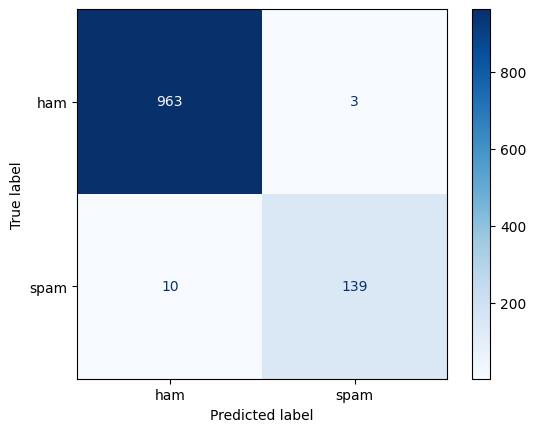

In [9]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sms['text'], sms['y'], test_size=0.2, random_state=42,
    stratify=sms['y'])

word_clf = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                              sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
word_clf.fit(X_tr, y_tr)
pred = word_clf.predict(X_te)
print(classification_report(y_te, pred, target_names=['ham', 'spam'],
                            digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                       display_labels=['ham', 'spam']).plot(cmap='Blues')
plt.show()

**Word model on the test set**

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| ham | 0.990 | 0.997 | 0.993 | 966 |
| spam | 0.979 | 0.933 | 0.955 | 149 |
| **accuracy** | | | **0.988** | 1,115 |
| **macro avg** | 0.984 | 0.965 | **0.974** | 1,115 |

The confusion matrix shows 13 mistakes in total: **10 spam messages missed** (recall 0.933 means 139 of 149 caught) and **3 ham messages flagged** as spam.

### 2.3 What did the word model learn?
Largest positive and negative coefficients of the logistic regression:

In [10]:
tfidf_step = word_clf.named_steps['tfidf']
w = word_clf.named_steps['model'].coef_[0]
terms = tfidf_step.get_feature_names_out()
order = np.argsort(w)
print('Most spam-like :', list(terms[order[-12:]][::-1]))
print('Most ham-like  :', list(terms[order[:12]]))

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like  : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


| Direction | Terms (from the output) | Interpretation |
|---|---|---|
| **Spam-like** | call, txt, free, text, reply, uk, to, www, mobile, claim, stop, your | `txt`, `claim`, `free`, `www`, `stop`, `reply`, `mobile` are how promotions ask for an action |
| **Ham-like** | my, me, ok, that, it, but, ll, gt, lt, can, what, da | Personal chat words |

> **Shortcuts, not understanding.** Several features describe the *dataset*, not spam itself: `uk` reflects where the data was collected, `to` and `your` are common words that happen to be frequent in spam here, `gt` / `lt` are leftovers of the HTML codes `&gt;` and `&lt;` in friends' texts, `ll` is what remains of "I'll", and `da` is chat slang. The model partly learns the **style of the corpus**.

### 2.4 Character model and head-to-head comparison

In [11]:
char_clf = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                              min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
char_clf.fit(X_tr, y_tr)

for name, clf in [('word 1-2 grams', word_clf), ('char 2-5 grams', char_clf)]:
    p = clf.predict(X_te)
    print(f'{name:15s} macro-F1 {f1_score(y_te, p, average="macro"):.3f}   '
          f'features {len(clf.named_steps["tfidf"].vocabulary_):,}')

print()
for name, clf in [('word', word_clf), ('char', char_clf)]:
    print(name)
    print(classification_report(y_te, clf.predict(X_te),
                                target_names=['ham', 'spam'], digits=3))

# Robustness to spelling tricks (the lab's two examples)
tricky = ['W1N a FR33 pr1ze!! txt CLAIM now', 'kal milte hain, 5 baje']
print('word:', dict(zip(tricky, word_clf.predict_proba(tricky)[:, 1].round(2))))
print('char:', dict(zip(tricky, char_clf.predict_proba(tricky)[:, 1].round(2))))

word 1-2 grams  macro-F1 0.974   features 12,128
char 2-5 grams  macro-F1 0.982   features 36,449

word
              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115

char
              precision    recall  f1-score   support

         ham      0.993     0.998     0.995       966
        spam      0.986     0.953     0.969       149

    accuracy                          0.992      1115
   macro avg      0.989     0.975     0.982      1115
weighted avg      0.992     0.992     0.992      1115

word: {'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.99), 'kal milte hain, 5 baje': np.float64(0.19)}
char: {'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.85), 'kal milte hain, 5 baje': np.float64(0.12)}


| Metric (test set) | Word 1-2 grams | Char 2-5 grams | Better |
|---|---|---|---|
| Features learned | 12,128 | 36,449 | Word (3x smaller) |
| **Macro-F1** | 0.974 | **0.982** | Char |
| Spam precision | 0.979 | **0.986** | Char |
| Spam recall | 0.933 | **0.953** | Char |
| Accuracy | 0.988 | **0.992** | Char |

In message counts the word model caught 139 of 149 spam messages with 3 false alarms; the character model caught about 142 with about 2 false alarms (derived from the rounded precision and recall).

> **Conclusion.** The character model is better on every metric, but the margin is small (**+0.008 macro-F1**) and comes from **one split of 1,115 messages**, so it is a consistent edge, not proof. The price is about **3x as many features**.

**Robustness to spelling tricks (the lab's two examples, spam probability)**

| Message | True class | Word | Char |
|---|---|---|---|
| `W1N a FR33 pr1ze!! txt CLAIM now` | spam | 0.99 | 0.85 |
| `kal milte hain, 5 baje` | ham | 0.19 | 0.12 |

Both models handle the lab's examples. Note that the word model is even more confident on the leetspeak spam here, because `txt`, `claim` and `now` survive the disguise.

### 2.5 My own test messages (Roman Urdu)
Two messages that the training data has never seen: a **genuine Roman Urdu request** and a **disguised local scam**.

In [12]:
mine = ['Yaar abhi call utha lo, free ho to mobile mein load daal dena, zaroori hai',
        'PayNow acc0unt b1ocked! Cl1ck www.paynow-verify.pk 2 cla1m Rs8000 b0nus 2day']
print('word:', dict(zip(mine, word_clf.predict_proba(mine)[:, 1].round(2))))
print('char:', dict(zip(mine, char_clf.predict_proba(mine)[:, 1].round(2))))

word: {'Yaar abhi call utha lo, free ho to mobile mein load daal dena, zaroori hai': np.float64(0.88), 'PayNow acc0unt b1ocked! Cl1ck www.paynow-verify.pk 2 cla1m Rs8000 b0nus 2day': np.float64(0.66)}
char: {'Yaar abhi call utha lo, free ho to mobile mein load daal dena, zaroori hai': np.float64(0.5), 'PayNow acc0unt b1ocked! Cl1ck www.paynow-verify.pk 2 cla1m Rs8000 b0nus 2day': np.float64(0.65)}


| Message | True class | Word | Char | Reading |
|---|---|---|---|---|
| `Yaar abhi call utha lo, free ho to mobile mein load daal dena, zaroori hai` | ham | **0.88** | **0.50** | Both models lean to spam; the char model sits exactly on the 0.5 threshold |
| `PayNow acc0unt b1ocked! Cl1ck www.paynow-verify.pk 2 cla1m Rs8000 b0nus 2day` | spam | 0.66 | 0.65 | Caught by both, but only with weak confidence |

**Why the ordinary message is flagged.** It contains `call`, `free` and `mobile`, three of the word model's most spam-like terms (Section 2.3). The Urdu words around them are unseen and contribute nothing. The model responds to **vocabulary, not meaning**. The character model is calmer (0.50 vs 0.88) but still borderline.

**Why the scam is only weakly caught.** Scattered digits (`acc0unt`, `b1ocked`, `cla1m`) and an invented brand (`PayNow`) produce n-grams neither model has seen. Character n-grams helped on the lab's `W1N / FR33` example but did **not** beat the word model here (0.65 vs 0.66).

### 2.6 Error analysis (word model)
All 13 mistakes, sorted by spam probability:

In [13]:
p_te = word_clf.predict_proba(X_te)[:, 1]
err = pd.DataFrame({'text': X_te, 'true': y_te, 'p_spam': p_te})
err = err[(err.p_spam >= 0.5) != (err.true == 1)]
pd.set_option('display.max_colwidth', 90)
print(err.sort_values('p_spam').to_string())

                                                                                                                                                                                       text  true    p_spam
750                                                                                  Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?     1  0.087598
2246  Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!     1  0.144048
3979                                                                                                                                                                     ringtoneking 84484     1  0.192426
1429                                                                                                                For sale - arsenal dartboard. Good condition but no doubles or trebl

The verdict column is **my own judgement** from the message content; I cannot see how the original annotators decided.

| # | Message (shortened) | True | P(spam) | Verdict | Reason |
|---|---|---|---|---|---|
| 1 | "old ladies running around with tattoos" | spam | 0.09 | **Label error** | Pure joke, no spam signal |
| 2 | "Hi ya babe ... scammers getting smart" | spam | 0.14 | **Ambiguous** | A warning about spam, written like the spam it describes |
| 3 | "ringtoneking 84484" | spam | 0.19 | **Model error** | Two tokens, too little evidence |
| 4 | "arsenal dartboard for sale" | spam | 0.21 | **Label error** | Reads like an ordinary classified ad |
| 5 | "ROMCAPspam ... breath of sunshine" | spam | 0.25 | **Model error** | Horoscope subscription; the clue is one rare token |
| 6 | "Sorry I missed your call ... 07090201529" | spam | 0.28 | **Model error** | Only clue is the premium `070` number prefix, which word tokens ignore |
| 7 | "Police station toilet stolen" | spam | 0.31 | **Ambiguous** | Joke-of-the-day subscription, no spam words |
| 8 | "FreeMsg Hey there darling ..." | spam | 0.41 | **Model error** | Obvious spam just below the 0.5 threshold |
| 9 | "Download as many ringtones ... Txt Sir to 80082" | spam | 0.42 | **Model error** | Obvious spam just below the threshold |
| 10 | "Can U get 2 phone NOW ... 09096102316" | spam | 0.46 | **Model error** | Chatty tone pulled it down; premium-rate number ignored |
| 11 | "We have sent JD for Customer Service ... ur mail id" | ham | 0.62 | **Ambiguous** | Could be a real recruiter or a job-ad scam |
| 12 | "Ok... Ur typical reply..." | ham | 0.64 | **Model error** | Plain chat; `ur` pushed it the wrong way |
| 13 | "Waiting for your call." | ham | 0.85 | **Model error** | `call` and `your` are two of its top spam shortcuts |

| Verdict | Count |
|---|---|
| Model errors | 8 |
| Label errors | 2 |
| Ambiguous | 3 |

> **Findings.** At least **5 of 13** mistakes are not really the model's fault, so the ceiling of this dataset is below 100 %. Model errors cluster in two groups: three spam misses sit between **0.41 and 0.46**, just under the threshold (a lower threshold might recover them, but it must be tested on *all* messages, not only the errors); and several depend on **phone-number prefixes** (`070`, `090`) that word tokens cannot capture. A **regex feature** (Part 4) could supply exactly that.

### 2.7 Limitations and conclusion

- **Random split is optimistic.** Test messages come from the same collection as the training messages. Real future messages change (new scams, new wording, Roman Urdu), as the two messages in Section 2.5 showed.
- **Language and region.** The data is English and UK-heavy.
- **Conclusion.** The character model is better here (macro-F1 **0.982 vs 0.974**, spam recall **0.953 vs 0.933**), but both models rely on vocabulary shortcuts and both struggled with an ordinary Roman Urdu message.

[Back to top](#top)

<a id="part3"></a>
---
## Part 3: Named Entity Recognition (NER), Measured

### Scoring rule
An entity counts as correct only if its **exact text and exact label** both match the gold answer.

| Metric | Definition |
|---|---|
| **Precision** | correct / predicted |
| **Recall** | correct / gold |
| **F1** | `2PR / (P + R)` |

A correct entity with a wrong boundary or label earns **zero** credit: it counts as one false positive **and** one miss.

### 3.1 Provided six-sentence set (out of the box)
16 gold entities. spaCy's small English model is used without changes.

In [14]:
sentences = [
    'Dr. Rabia Anwar at CMH Faisalabad reviewed it on 12 September 2026.',
    'The invoice from Sitara Chemicals for PKR 72,500 is due on 30/09/2026.',
    'Farmer Hamza Qureshi from Sialkot reported leaf rust in his wheat crop.',
    'Call Zong support at 0345-8765432 or email help@zong.com.pk.',
    'Askari Bank approved a loan of Rs. 480,000 for Mehwish Tariq.',
    'The consignment left Gwadar Port on Monday for Quetta.']
for s in sentences:
    doc = nlp(s)
    print([(e.text, e.label_) for e in doc.ents])

[('Rabia Anwar', 'PERSON'), ('Faisalabad', 'PERSON'), ('12 September 2026', 'DATE')]
[('Sitara Chemicals', 'ORG'), ('PKR 72,500', 'ORG'), ('30/09/2026', 'GPE')]
[('Farmer Hamza Qureshi', 'ORG'), ('Sialkot', 'PERSON')]
[('Call Zong', 'PERSON'), ('0345-8765432', 'DATE')]
[('Askari Bank', 'ORG'), ('480,000', 'CARDINAL')]
[('Gwadar Port', 'FAC'), ('Monday', 'DATE'), ('Quetta', 'ORG')]


In [15]:
gold = [
    {('Rabia Anwar', 'PERSON'), ('CMH', 'ORG'), ('Faisalabad', 'GPE'),
     ('12 September 2026', 'DATE')},
    {('Sitara Chemicals', 'ORG'), ('PKR 72,500', 'MONEY'),
     ('30/09/2026', 'DATE')},
    {('Hamza Qureshi', 'PERSON'), ('Sialkot', 'GPE')},
    {('Zong', 'ORG')},
    {('Askari Bank', 'ORG'), ('Rs. 480,000', 'MONEY'),
     ('Mehwish Tariq', 'PERSON')},
    {('Gwadar Port', 'FAC'), ('Monday', 'DATE'), ('Quetta', 'GPE')}]

def ner_scores(nlp_model):
    tp = fp = fn = 0
    for s, g in zip(sentences, gold):
        pred = {(e.text, e.label_) for e in nlp_model(s).ents}
        tp += len(pred & g)
        fp += len(pred - g)
        fn += len(g - pred)
    p, r = tp / (tp + fp), tp / (tp + fn)
    return {'precision': round(p, 3), 'recall': round(r, 3),
            'f1': round(2 * p * r / (p + r), 3)}

print('spaCy out of the box:', ner_scores(nlp))

spaCy out of the box: {'precision': 0.4, 'recall': 0.375, 'f1': 0.387}


**Score:** precision 0.400, recall 0.375, **F1 = 0.387** (TP 6, FP 9, FN 10).

Every sentence contains a systematic error:

| Sentence | spaCy predicted | Should be |
|---|---|---|
| `Dr. Rabia Anwar at CMH Faisalabad ...` | Faisalabad = PERSON; **CMH missed** | Faisalabad = GPE, CMH = ORG |
| `... invoice from Sitara Chemicals for PKR 72,500 ... 30/09/2026` | `PKR 72,500` = ORG; `30/09/2026` = GPE | MONEY; DATE |
| `Farmer Hamza Qureshi from Sialkot ...` | `Farmer Hamza Qureshi` = ORG; Sialkot = PERSON | PERSON (without "Farmer"); GPE |
| `Call Zong support at 0345-8765432 ...` | `Call Zong` = PERSON; phone number = DATE | `Zong` = ORG; phone is not a date |
| `Askari Bank approved ... Rs. 480,000 for Mehwish Tariq` | `480,000` = CARDINAL (lost "Rs."); **Mehwish Tariq missed** | MONEY; PERSON |
| `... left Gwadar Port on Monday for Quetta` | Quetta = ORG | GPE |

> **Pattern.** Three kinds of failure repeat: (a) **place and person names the small model has not seen** (Faisalabad, Sialkot, Quetta), (b) **formats** (money, numeric dates, phone numbers), and (c) **boundaries** ("Farmer ...", "Call ...").

### 3.2 Adding rules (EntityRuler)
Money pattern (PKR / Rs / Rs. + number), a numeric-date regex, and a short list of literal names (Sitara Chemicals, Askari Bank, CMH, Zong, Gwadar Port).

In [16]:
nlp_base = spacy.load('en_core_web_sm')     # untouched copy for "before" scores

ruler = nlp.add_pipe('entity_ruler', before='ner')
ruler.add_patterns([
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    {'label': 'ORG', 'pattern': 'Sitara Chemicals'},
    {'label': 'ORG', 'pattern': 'Askari Bank'},
    {'label': 'ORG', 'pattern': 'CMH'},
    {'label': 'ORG', 'pattern': 'Zong'},
    {'label': 'FAC', 'pattern': 'Gwadar Port'},
    {'label': 'DATE',
     'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
])
print('spaCy + entity ruler:', ner_scores(nlp))

spaCy + entity ruler: {'precision': 0.688, 'recall': 0.688, 'f1': 0.688}


| Setting | TP | FP | FN | Precision | Recall | F1 |
|---|---|---|---|---|---|---|
| spaCy out of the box | 6 | 9 | 10 | 0.400 | 0.375 | **0.387** |
| spaCy + entity ruler | 11 | 5 | 5 | 0.688 | 0.688 | **0.688** |

Rules lift F1 by **+0.301**. The ruler contains no city names, so unseen places are the likely remaining weak point (the five remaining errors were not printed, so this is an inference).

> **Note.** The weak baseline is largely caused by less common place names: Faisalabad, Sialkot and Quetta were all mis-tagged in the output above. The before / after comparison is valid *within* this notebook, but the absolute numbers depend on which names are used.

### 3.3 My own domain: malaria diagnosis and medical labs
**10 sentences, 36 gold entities**, split to avoid fooling myself:

| Set | Sentences | Gold entities | Role |
|---|---|---|---|
| **Rule-writing set** | 1-5 | 18 | I read the model's output here and design rules from it |
| **Held-out set** | 6-10 | 18 | I do **not** read the output while writing rules |

One consistency fix was made to the gold standard: the number `12` in sentence 1 is tagged by spaCy, and the equivalent `40` in sentence 10 was already annotated. Adding `('12', 'CARDINAL')` keeps annotation consistent; otherwise the score would measure my inconsistency, not the model.

My rules: a **money** pattern, a **numeric-date** regex, a **phone** pattern (so phone numbers are not read as dates; ignored in scoring because phones are handled by regex in Part 4), literal names **CMH, Faisalabad, Gujranwala**, and one **shape rule**: capitalised words followed by *lab, laboratory, hospital* or *international*. I deliberately did **not** add Quetta, Hyderabad or Sukkur, because they appear only in the held-out set.

In [17]:
import spacy
nlp_base = spacy.load('en_core_web_sm')

dom_sents = [
    # --- rule-writing set (1-5) ---
    'Dr. Rabia Anwar at CMH Faisalabad reported 12 parasitized smears on 05/10/2026.',
    'Citi Lab charged PKR 2,800 for a blood smear test on 14/10/2026.',
    'Hamza Qureshi from Gujranwala was treated for malaria at Services Hospital on Friday.',
    'Mehwish Tariq paid Rs. 650 at Bahria International in Faisalabad.',
    'Call the Noor Laboratory at 0333-9087654 about the slides due on 20 November 2026.',
    # --- held-out test set (6-10) ---
    'Nimra Sheikh from Quetta visited Jinnah Hospital on Tuesday with fever.',
    'The Sindh Health Department bought test kits for PKR 390,000 on 03/11/2026.',
    'Areeba Javed donated Rs. 22,000 to Chhipa Foundation in Hyderabad.',
    'Red Crescent Society opened a malaria clinic in Sukkur on 25 December 2026.',
    'Fahad Mirza reported 40 infected cells at Liaquat University Hospital on Sunday.']

dom_gold = [
    {('Rabia Anwar', 'PERSON'), ('CMH', 'ORG'), ('Faisalabad', 'GPE'),
     ('05/10/2026', 'DATE')},
    {('Citi Lab', 'ORG'), ('PKR 2,800', 'MONEY'), ('14/10/2026', 'DATE')},
    {('Hamza Qureshi', 'PERSON'), ('Gujranwala', 'GPE'),
     ('Services Hospital', 'ORG'), ('Friday', 'DATE')},
    {('Mehwish Tariq', 'PERSON'), ('Rs. 650', 'MONEY'),
     ('Bahria International', 'ORG'), ('Faisalabad', 'GPE')},
    {('Noor Laboratory', 'ORG'), ('20 November 2026', 'DATE')},
    # held-out
    {('Nimra Sheikh', 'PERSON'), ('Quetta', 'GPE'), ('Jinnah Hospital', 'ORG'),
     ('Tuesday', 'DATE')},
    {('Sindh Health Department', 'ORG'), ('PKR 390,000', 'MONEY'),
     ('03/11/2026', 'DATE')},
    {('Areeba Javed', 'PERSON'), ('Rs. 22,000', 'MONEY'),
     ('Chhipa Foundation', 'ORG'), ('Hyderabad', 'GPE')},
    {('Red Crescent Society', 'ORG'), ('Sukkur', 'GPE'),
     ('25 December 2026', 'DATE')},
    {('Fahad Mirza', 'PERSON'), ('40', 'CARDINAL'),
     ('Liaquat University Hospital', 'ORG'), ('Sunday', 'DATE')}]

def score_on(model, sents, gold_sets):
    tp = fp = fn = 0
    for s, g in zip(sents, gold_sets):
        pred = {(e.text, e.label_) for e in model(s).ents}
        tp += len(pred & g); fp += len(pred - g); fn += len(g - pred)
    p, r = tp / (tp + fp), tp / (tp + fn)
    return {'precision': round(p, 3), 'recall': round(r, 3),
            'f1': round(2 * p * r / (p + r), 3)}

print('BEFORE rules, sentences 1-5 :', score_on(nlp_base, dom_sents[:5], dom_gold[:5]))
print('BEFORE rules, held-out 6-10 :', score_on(nlp_base, dom_sents[5:], dom_gold[5:]))
print()
for s in dom_sents[:5]:        # study ONLY the first five to design rules
    print([(e.text, e.label_) for e in nlp_base(s).ents])

BEFORE rules, sentences 1-5 : {'precision': 0.5, 'recall': 0.471, 'f1': 0.485}
BEFORE rules, held-out 6-10 : {'precision': 0.556, 'recall': 0.556, 'f1': 0.556}

[('Rabia Anwar', 'PERSON'), ('12', 'CARDINAL')]
[('Citi Lab', 'PERSON'), ('PKR 2,800', 'LAW'), ('14/10/2026', 'DATE')]
[('Hamza Qureshi', 'PERSON'), ('Gujranwala', 'GPE'), ('Services Hospital', 'ORG'), ('Friday', 'DATE')]
[('Tariq', 'PERSON'), ('650', 'CARDINAL'), ('Bahria International', 'FAC'), ('Faisalabad', 'GPE')]
[('the Noor Laboratory', 'ORG'), ('0333-9087654', 'DATE'), ('20 November 2026', 'DATE')]


In [18]:
dom_gold[0].add(('12', 'CARDINAL'))      # consistent annotation fix

nlp_dom = spacy.load('en_core_web_sm')
ruler = nlp_dom.add_pipe('entity_ruler', before='ner')
ruler.add_patterns([
    # money formats
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    # numeric dates like 05/10/2026
    {'label': 'DATE',
     'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
    # mobile numbers, claimed so they are not read as dates (handled by regex in Part 4)
    {'label': 'PHONE',
     'pattern': [{'TEXT': {'REGEX': r'^0\d{3}-\d{7}$'}}]},
    # names seen in sentences 1-5
    {'label': 'ORG', 'pattern': 'CMH'},
    {'label': 'GPE', 'pattern': 'Faisalabad'},
    {'label': 'GPE', 'pattern': 'Gujranwala'},
    # shape rule: capitalised words ending in a lab/hospital word
    {'label': 'ORG',
     'pattern': [{'IS_TITLE': True, 'OP': '+'},
                 {'LOWER': {'IN': ['lab', 'laboratory', 'hospital',
                                   'international']}}]},
])

def score_dom(model, sents, gold_sets, ignore=('PHONE',)):
    tp = fp = fn = 0
    for s, g in zip(sents, gold_sets):
        pred = {(e.text, e.label_) for e in model(s).ents if e.label_ not in ignore}
        tp += len(pred & g); fp += len(pred - g); fn += len(g - pred)
    p, r = tp / (tp + fp), tp / (tp + fn)
    return {'precision': round(p, 3), 'recall': round(r, 3),
            'f1': round(2 * p * r / (p + r), 3)}

print('BEFORE, sentences 1-5 :', score_dom(nlp_base, dom_sents[:5], dom_gold[:5]))
print('BEFORE, held-out 6-10 :', score_dom(nlp_base, dom_sents[5:], dom_gold[5:]))
print('AFTER , sentences 1-5 :', score_dom(nlp_dom, dom_sents[:5], dom_gold[:5]))
print('AFTER , held-out 6-10 :', score_dom(nlp_dom, dom_sents[5:], dom_gold[5:]))
print()
for s in dom_sents[5:]:
    print([(e.text, e.label_) for e in nlp_dom(s).ents if e.label_ != 'PHONE'])

BEFORE, sentences 1-5 : {'precision': 0.562, 'recall': 0.5, 'f1': 0.529}
BEFORE, held-out 6-10 : {'precision': 0.556, 'recall': 0.556, 'f1': 0.556}
AFTER , sentences 1-5 : {'precision': 0.895, 'recall': 0.944, 'f1': 0.919}
AFTER , held-out 6-10 : {'precision': 0.778, 'recall': 0.778, 'f1': 0.778}

[('Nimra Sheikh', 'PERSON'), ('Quetta', 'ORG'), ('Jinnah Hospital', 'ORG'), ('Tuesday', 'DATE')]
[('The Sindh Health Department', 'ORG'), ('PKR 390,000', 'MONEY'), ('03/11/2026', 'DATE')]
[('Areeba Javed', 'LOC'), ('Rs. 22,000', 'MONEY'), ('Chhipa Foundation', 'ORG'), ('Hyderabad', 'GPE')]
[('Red Crescent Society', 'ORG'), ('Sukkur', 'ORG'), ('25 December 2026', 'DATE')]
[('Fahad Mirza', 'PERSON'), ('40', 'CARDINAL'), ('Liaquat University Hospital', 'ORG'), ('Sunday', 'DATE')]


**Baseline errors on the rule-writing sentences (before rules)**

| Gold | spaCy produced |
|---|---|
| Citi Lab = ORG | **PERSON** |
| PKR 2,800 = MONEY | **LAW** |
| Mehwish Tariq = PERSON | only **Tariq** (boundary) |
| Rs. 650 = MONEY | `650` = CARDINAL |
| Bahria International = ORG | **FAC** |
| Noor Laboratory = ORG | `the Noor Laboratory` (boundary includes "the") |
| CMH, Faisalabad (sentence 1), `05/10/2026` | **not found** |
| (not in gold) | phone number `0333-9087654` tagged DATE |

**Scores before and after the rules**

| Set | F1 before | Precision / Recall after | F1 after | Gain |
|---|---|---|---|---|
| Sentences 1-5 (rules written from these) | 0.529 | 0.895 / 0.944 | **0.919** | +0.390 |
| Sentences 6-10 (**held out**) | 0.556 | 0.778 / 0.778 | **0.778** | +0.222 |

**How to read the two gains**

- The 0.919 on sentences 1-5 is **not** a result to quote: the rules were written while looking at exactly those errors.
- The held-out gain (**10 to 14 correct entities out of 18**) is the honest estimate, and it is smaller (+0.222 against +0.390).
- The two baselines are similar (0.529 vs 0.556), so the difference in gains is **not** explained by one set being easier.
- With only 18 held-out entities, **one entity moves F1 by about 0.056**, so the third decimal should not be interpreted.
- My best guess is that the **shape rule** is what carried over to unseen hospital names (it describes a pattern), while literal names could only help the sentences they came from. I did not log which rule fixed which entity, so this is a hypothesis, not a measured per-rule contribution.

**The four errors that remain on the held-out set**

| spaCy + rules produced | Gold | Cause | Best fix |
|---|---|---|---|
| `Quetta` = **ORG** | GPE | Unseen city name | Gazetteer or trained model |
| `Sukkur` = **ORG** | GPE | Unseen city name | Gazetteer or trained model |
| `Areeba Javed` = **LOC** | PERSON | Unseen person name | Trained model |
| `The Sindh Health Department` | `Sindh Health Department` | Leading "The" included in the span | **Rule**: strip leading determiners from every ORG span |

The first three share one cause (names the small model has never seen), the last is a closed, well-defined boundary problem.

### 3.4 Which tool for which error

| Error type | Right tool | Why |
|---|---|---|
| Boundary ("The ...") | **Rule** | Closed problem; training a model would be wasteful |
| Open-ended names (hospitals, cities, people) | **Model trained on my own annotated data** | Rules only know the names I typed and keep leaking; needs a few hundred labelled sentences, which I do not have yet |
| Fixed formats (dates, money, phones) | **Regex** (Part 4) | Names have no fixed format, formats do |

### 3.5 Limitation and conclusion
Ten sentences and 36 entities are **too few** to establish general NER performance. The result shows a **direction** (rules help formats and known names, and generalise only through patterns), not a precise number.

> **Conclusion.** Rules raised F1 from **0.387 to 0.688** on the provided sentences and from **0.556 to 0.778** on unseen domain sentences. The gap between the *seen* and *unseen* gain is the lesson: a rule set always looks best on the sentences it was written from, so the **held-out number** is the one to trust.

[Back to top](#top)

<a id="part4"></a>
---
## Part 4: Regex Fields with Negative Tests

### The idea
A regex is a **stencil**: a good one fits the wanted shape and **nothing else**. Testing only with positive examples never exposes a sloppy pattern, so every pattern is also run on text that **must stay unmatched**.

### Patterns
The six standard patterns (CNIC, mobile, amount, date, email, invoice) plus **three for my malaria / lab domain**:

| Field | Pattern | Matches | Example |
|---|---|---|---|
| `slide_id` | `\bSL-\d{4}\b` | `SL-` + **exactly 4 digits** | `SL-2041` |
| `temp` | `\b(?:3[5-9]\|4[0-2])(?:\.\d)?\s?°C` | Body temperature **35 to 42 °C**, at most one decimal | `39.5 °C` |
| `hb` | `\bHb\s?:?\s?(\d{1,2}(?:\.\d)?)\s?g/dL` | Haemoglobin, at most one decimal | `Hb 9.8 g/dL` |

In [19]:
import re

PATTERNS = {
    'cnic':     r'\b\d{5}-\d{7}-\d\b',
    'mobile':   r'(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b',
    'amount':   r'(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',
    'date':     r'\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b',
    'email':    r'\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b',
    'invoice':  r'\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b',
    # my malaria / lab domain
    'slide_id': r'\bSL-\d{4}\b',
    'temp':     r'\b(?:3[5-9]|4[0-2])(?:\.\d)?\s?°C',
    'hb':       r'\bHb\s?:?\s?(\d{1,2}(?:\.\d)?)\s?g/dL',
}

def extract_fields(text):
    out = {}
    for name, pat in PATTERNS.items():
        hits = re.findall(pat, text, flags=re.IGNORECASE)
        if hits:
            out[name] = hits
    return out

def mask_pii(text):
    text = re.sub(PATTERNS['cnic'], '[CNIC]', text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'], '[EMAIL]', text)
    return text

lab_tests = [
    ('CNIC 61101-7654321-9, mobile +92 311 7654321', True),
    ('Total Rs. 9,750.25 paid on 05/10/2026', True),
    ('Invoice No. 4417 from info@sitara.com.pk', True),
    ('Order 12345678901234 shipped', False),
    ('Room 0300 on floor 3', False),
]
for text, expect in lab_tests:
    print(f'{str(expect):5s} {extract_fields(text)} <- {text}')

my_tests = [
    ('Slide SL-2041, temp 39.5 °C, Hb 9.8 g/dL, mobile 0333-9087654',
     {'slide_id', 'temp', 'hb', 'mobile'}),
    ('Slide SL-0312 read on 14/10/2026, charged Rs. 3,200',
     {'slide_id', 'date', 'amount'}),
    ('SL-12 is mislabelled', set()),            # negative: 2 digits
    ('SL-12345 is mislabelled', set()),         # negative: 5 digits
    ('Room temperature 25 °C', set()),          # negative: not fever range
    ('Hb 9.88 g/dL', set()),                    # negative: 2 decimals
    ('Ticket 123456789012 raised', set()),      # negative: long number
]
print()
for text, expected in my_tests:
    got = set(extract_fields(text))
    print('PASS' if got == expected else 'FAIL', got, '<-', text)

# sloppy vs final, to show over-matching
bad = {'slide_id': r'SL-\d+', 'temp': r'\d{2}(?:\.\d)?\s?°C',
       'cnic': r'\d{5}-?\d{7}-?\d', 'mobile': r'3\d{2}[- ]?\d{7}'}
cases = [('SL-12345 is mislabelled', 'slide_id'),
         ('Room temperature 25 °C', 'temp'),
         ('Order 12345678901234 shipped', 'cnic'),
         ('Ref 9300123456789 closed', 'mobile')]
print()
for text, name in cases:
    print(f'{name:8s} sloppy: {re.findall(bad[name], text)} | final: {re.findall(PATTERNS[name], text)} <- {text}')

True  {'cnic': ['61101-7654321-9'], 'mobile': ['+92 311 7654321']} <- CNIC 61101-7654321-9, mobile +92 311 7654321
True  {'amount': ['9,750.25'], 'date': ['05/10/2026']} <- Total Rs. 9,750.25 paid on 05/10/2026
True  {'email': ['info@sitara.com.pk'], 'invoice': ['4417']} <- Invoice No. 4417 from info@sitara.com.pk
False {} <- Order 12345678901234 shipped
False {} <- Room 0300 on floor 3

PASS {'temp', 'slide_id', 'mobile', 'hb'} <- Slide SL-2041, temp 39.5 °C, Hb 9.8 g/dL, mobile 0333-9087654
PASS {'date', 'slide_id', 'amount'} <- Slide SL-0312 read on 14/10/2026, charged Rs. 3,200
PASS set() <- SL-12 is mislabelled
PASS set() <- SL-12345 is mislabelled
PASS set() <- Room temperature 25 °C
PASS set() <- Hb 9.88 g/dL
PASS set() <- Ticket 123456789012 raised

slide_id sloppy: ['SL-12345'] | final: [] <- SL-12345 is mislabelled
temp     sloppy: ['25 °C'] | final: [] <- Room temperature 25 °C
cnic     sloppy: ['1234567890123'] | final: [] <- Order 12345678901234 shipped
mobile   sloppy: ['

### Results: 12 of 12 cases behaved as expected

| Test text | Should find | Result |
|---|---|---|
| CNIC 61101-7654321-9, mobile +92 311 7654321 | cnic, mobile | found both |
| Total Rs. 9,750.25 paid on 05/10/2026 | amount, date | found both |
| Invoice No. 4417 from info@sitara.com.pk | invoice, email | found both |
| Order 12345678901234 shipped | nothing | `{}` |
| Room 0300 on floor 3 | nothing | `{}` |
| Slide SL-2041, temp 39.5 °C, Hb 9.8 g/dL, mobile 0333-9087654 | slide_id, temp, hb, mobile | **PASS** |
| Slide SL-0312 read on 14/10/2026, charged Rs. 3,200 | slide_id, date, amount | **PASS** |
| SL-12 is mislabelled | nothing | **PASS** |
| SL-12345 is mislabelled | nothing | **PASS** |
| Room temperature 25 °C | nothing | **PASS** |
| Hb 9.88 g/dL | nothing | **PASS** |
| Ticket 123456789012 raised | nothing | **PASS** |

(5 lab cases + 7 of my own, of which 5 are negative tests.)

### Why each negative case fails to match

| Negative text | Reason it stays unmatched |
|---|---|
| `Order 12345678901234` | CNIC needs the shape **5 - 7 - 1 digits with hyphens** and word boundaries; a bare 14-digit run cannot match |
| `Room 0300 on floor 3` | A mobile needs prefix `+92` or `0`, then `3`, two more digits and **exactly 7** digits; `0300` is only 4 |
| `SL-12`, `SL-12345` | Slide ID demands **exactly four digits** followed by a boundary |
| `Room temperature 25 °C` | 25 is outside **35-42**, so an air temperature is never logged as a fever |
| `Hb 9.88 g/dL` | Only **one decimal** allowed; two decimals look like a typo or misread |
| `Ticket 123456789012` | No hyphens and no `0` / `+92` prefix, so neither CNIC nor mobile |

### Sloppy versus final patterns
Four deliberately loose patterns were run on text chosen to attack them. Because I chose these cases, the **4 of 4** failures show what each loose pattern *allows*, not how often it would fail in practice.

| Field | Sloppy pattern | Attack text | Sloppy match | Final match |
|---|---|---|---|---|
| Slide ID | `SL-\d+` | SL-12345 is mislabelled | `SL-12345` | **none** |
| Temperature | `\d{2}(?:\.\d)?\s?°C` | Room temperature 25 °C | `25 °C` | **none** |
| CNIC | `\d{5}-?\d{7}-?\d` | Order 12345678901234 shipped | `1234567890123` | **none** |
| Mobile | `3\d{2}[- ]?\d{7}` | Ref 9300123456789 closed | `3001234567` | **none** |

### The pattern that matched too much: temperature
My first idea for a fever pattern was "two digits followed by °C". It matched `25 °C` in "Room temperature 25 °C", so a ward's air temperature would be logged as a **patient reading**, which in a fever record is a **harmful false positive**. Three changes fixed it:

1. **A numeric range** `3[5-9]|4[0-2]` allows only 35 to 42, the plausible span for a human body temperature.
2. **A word boundary** `\b` at the start, so the pattern cannot begin in the middle of a longer number.
3. **At most one decimal**, matching how thermometers report (39.5, not 39.52).

The CNIC and mobile patterns had a different flaw: the sloppy versions **cut a valid-looking number out of the middle of a longer one**. Boundaries, exact counts and a required prefix prevent that.

### Notes and limits
- `amount`, `invoice` and `hb` return only the **number**, because it sits in a capture group.
- A regex knows **shape, not meaning**. The temperature pattern would still accept `36 °C` in a sentence about a hot day, because 36 lies inside the fever range.
- `SL-dddd` is a format I **defined** for this lab; a real laboratory would use its own.
- A match proves that a string *looks like* a field, not that it is *true*.

> **Conclusion.** Regex is the right tool for **fixed-format fields** (IDs, phone numbers, dates, lab values); the NER model is for **free-form names**. In Part 6 this split mattered: the mobile regex masked the phone number correctly, while spaCy alone had labelled a phone number as a DATE in Part 3.

[Back to top](#top)

<a id="part5"></a>
---
## Part 5: Character Error Rate (CER) and OCR Repair

### The idea
OCR is a student copying a page by eye, and **CER is the marking scheme**:

$$\text{CER} = \frac{\text{Levenshtein distance (substitutions + deletions + insertions)}}{\text{length of the reference}}$$

The edit distance is implemented from scratch in `levenshtein()`. A CER of 0.062 means about 6 wrong characters per 100.

### Context rules instead of blind replacement
OCR engines confuse look-alike characters: the **letter O and digit 0**, and the **letters l / I and digit 1**. The rule is **not** "always replace O with 0" (that would damage real words). `fix_ocr` only acts when **digits surround** the character:

| Rule | Example |
|---|---|
| `O` or `o` next to digits becomes `0` | `3O/09/2O26` becomes `30/09/2026` |
| `l` or `I` between two digits becomes `1` | `4l7` becomes `417` |
| `N0.` becomes `No.` | `Invoice N0. 4417` becomes `Invoice No. 4417` |

In [20]:
import re

def levenshtein(a, b):
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, prev + (ca != cb))
    return d[len(b)]

def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)

def fix_ocr(text):
    text = re.sub(r'(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)', '0', text)
    text = re.sub(r'(?<=\d)[lI](?=\d)', '1', text)
    text = re.sub(r'\bN0\.', 'No.', text)
    return text

# The lab's three controlled error pairs (reference, OCR output)
pairs = [('Invoice No. 4417', 'Invoice N0. 4417'),
         ('Total: PKR 8,300', 'Total: PKR 8,3O0'),
         ('Due 30/09/2026', 'Due 3O/09/2O26')]
for ref, ocr in pairs:
    fixed = fix_ocr(ocr)
    print(f'{ocr:20s} CER {cer(ref, ocr):.3f}  ->  {fixed:20s} CER {cer(ref, fixed):.3f}')


Invoice N0. 4417     CER 0.062  ->  Invoice No. 4417     CER 0.000
Total: PKR 8,3O0     CER 0.062  ->  Total: PKR 8,300     CER 0.000
Due 3O/09/2O26       CER 0.143  ->  Due 30/09/2026       CER 0.000


**Results on three controlled error pairs**

| Reference | OCR output | Wrong chars | Length | CER before | CER after repair |
|---|---|---|---|---|---|
| `Invoice No. 4417` | `Invoice N0. 4417` | 1 | 16 | **0.062** | **0.000** |
| `Total: PKR 8,300` | `Total: PKR 8,3O0` | 1 | 16 | **0.062** | **0.000** |
| `Due 30/09/2026` | `Due 3O/09/2O26` | 2 | 14 | **0.143** | **0.000** |

The same kind of mistake counts for **more in a short string**: two errors in 14 characters (0.143) score worse than one error in 16 (0.062).

> **CER understates the damage.** `3O/09/2O26` is only 14 % wrong by character count, but the date regex from Part 4 requires digits and would **not match it at all**. One misread character can turn a field into a total miss, so repairing OCR output **before** extraction matters more than the small CER suggests.

### Real OCR test on a synthetic invoice
A five-line invoice image is drawn with Pillow and read with **EasyOCR**. Whitespace is normalised first, so line breaks do not count as errors.

using font: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf
invoice.png saved


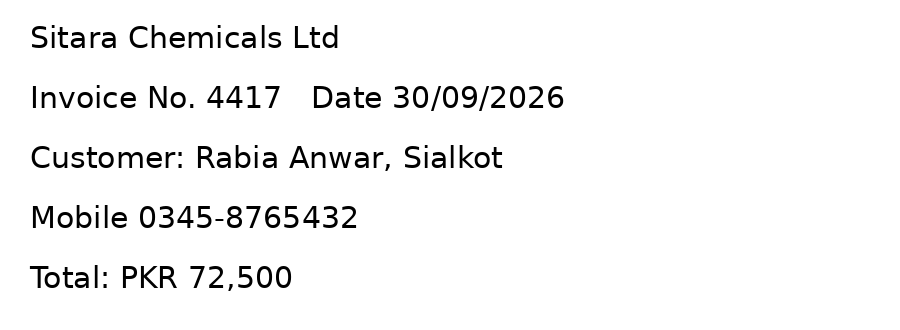

In [21]:
import os, matplotlib
from PIL import Image, ImageDraw, ImageFont

font = None
for fp in [os.path.join(matplotlib.get_data_path(), 'fonts', 'ttf', 'DejaVuSans.ttf'),
           '/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf']:
    try:
        font = ImageFont.truetype(fp, 30)
        print('using font:', fp)
        break
    except Exception as e:
        print('font failed:', fp, '->', e)
if font is None:
    font = ImageFont.load_default(size=30)
    print('using Pillow default font')

lines = ['Sitara Chemicals Ltd', 'Invoice No. 4417   Date 30/09/2026',
         'Customer: Rabia Anwar, Sialkot', 'Mobile 0345-8765432',
         'Total: PKR 72,500']
img = Image.new('RGB', (900, 330), 'white')
d = ImageDraw.Draw(img)
for k, line in enumerate(lines):
    d.text((30, 20 + 60 * k), line, fill='black', font=font)
img.save('invoice.png')
print('invoice.png saved')
img

In [22]:
# EasyOCR downloads its model the first time: turn Internet On in the Kaggle notebook settings.
import easyocr
reader = easyocr.Reader(['en'], gpu=False)
ocr_lines = reader.readtext('invoice.png', detail=0, paragraph=False)
ocr_text = ' '.join(ocr_lines)
print('EasyOCR output:', ocr_text)


Using CPU. Note: This module is much faster with a GPU.


EasyOCR output: Sitara Chemicals Ltd Invoice No. 4417 Date 30/09/2026 Customer: Rabia Anwar, Sialkot Mobile 0345-8765432 Total: PKR 72,500


In [23]:
norm = lambda s: ' '.join(s.split())
truth = norm(' '.join(lines))
raw, clean = norm(ocr_text), norm(fix_ocr(ocr_text))
print('TRUTH:', truth)
print('OCR  :', raw)
print(f'CER raw {cer(truth, raw):.3f}   after fixes {cer(truth, clean):.3f}')


TRUTH: Sitara Chemicals Ltd Invoice No. 4417 Date 30/09/2026 Customer: Rabia Anwar, Sialkot Mobile 0345-8765432 Total: PKR 72,500
OCR  : Sitara Chemicals Ltd Invoice No. 4417 Date 30/09/2026 Customer: Rabia Anwar, Sialkot Mobile 0345-8765432 Total: PKR 72,500
CER raw 0.000   after fixes 0.000


| Stage | Reference length | CER |
|---|---|---|
| Raw EasyOCR output | 122 characters | **0.000** |
| After `fix_ocr` | 122 characters | **0.000** |

The OCR text came back **identical** to the reference, so the repair rules had nothing to fix, and, importantly, they did **no harm**. A correction step must never damage text that was already correct.

### Why a perfect score does not predict real documents
This image is the **easy case**: computer-rendered, clean font at 30 px, black on pure white, perfectly straight, no noise. A phone photo of a real lab report adds:

| Real-world problem | Effect |
|---|---|
| Uneven lighting, shadows, glare | Faded or merged strokes |
| Rotation and perspective | Distorted characters |
| Blur and compression | `0` / `O` and `1` / `l` / `I` merge, exactly like the test pairs above |
| Stamps, handwriting, **Urdu text** mixed with English | An English-only reader fails on them |

I **expect** a raw CER of roughly 0.05 to 0.20 on my own scans, mostly in digits and punctuation. This is an expectation, **not a measurement**. To obtain a real number I would type the reference text of five reports by hand and score each with `cer()`.

### Risk of wrong automatic correction
A rule that turns O into 0 could silently change a **date, slide ID or lab value** into a different but valid-looking one, and nothing would flag it. This is why the rules act only in **digit contexts**, why they must be tested on **negative examples** (same discipline as Part 4), and why corrected values should still be **checked by a person**.

> **Conclusion.** CER gives OCR quality a **number**, but it must be read together with **what the errors do downstream**. The context rules fixed all three planned error patterns, but they only cover confusions I thought of in advance.

[Back to top](#top)

<a id="part6"></a>
---
## Part 6: Image + Text Case Record (with Privacy)

### The idea
Two assistants each provide **evidence**, and **neither decides**. One only looks at the blood-smear image, the other only reads the clinical note. The **record** is the folder that holds both reports side by side so a human can see **why** a case was sent forward.

```
 blood-smear image ──► ResNet-18 (Week 6) ──┐
                                            ├──► case record ──► REFER / ROUTINE ──► human
 clinical note ──► mask PII ──► spaCy + regex ┘
```

### 6.1 Privacy first: masking
`mask_pii` replaces CNIC numbers, mobile numbers and email addresses with placeholders. It runs **before** any entity or field extraction.

In [24]:
def mask_pii(text):
    """Hide personal identifiers before logging or sharing."""
    text = re.sub(PATTERNS['cnic'], '[CNIC]', text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'], '[EMAIL]', text)
    return text

print(mask_pii('CNIC 61101-7654321-9, call 0345-8765432, a@b.pk'))

CNIC [CNIC], call [PHONE], [EMAIL]


In [29]:
import os, glob, json, zipfile
import torch, torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
import spacy

try:
    nlp
except NameError:
    nlp = spacy.load('en_core_web_sm')

# --- checkpoint (repack the unpacked folder if needed) ---
# --- checkpoint ---
import glob

MODEL_DIR = '/kaggle/input/datasets/anderianisar/lab6-model-pt'

# 1) pehle dekho ke folder mein koi .pt / .pth file mojood hai
files = glob.glob(MODEL_DIR + '/**/*.pt', recursive=True) + \
        glob.glob(MODEL_DIR + '/**/*.pth', recursive=True)

if files:
    W6_PATH = files[0]
else:
    # 2) warna Kaggle ne .pt ko unzip kar diya hai: data.pkl dhoond kar dobara zip banao
    pkl = glob.glob(MODEL_DIR + '/**/data.pkl', recursive=True)
    src = os.path.dirname(pkl[0])
    W6_PATH = '/kaggle/working/week6_model.pt'
    with zipfile.ZipFile(W6_PATH, 'w', zipfile.ZIP_STORED) as z:
        for root, dirs, fs in os.walk(src):
            for f in fs:
                full = os.path.join(root, f)
                z.write(full, 'week6_model/' + os.path.relpath(full, src))

print('checkpoint:', W6_PATH)

ckpt = torch.load(W6_PATH, map_location='cpu', weights_only=False)
classes = ckpt['classes']
print('backbone:', ckpt['backbone'], '| img_size:', ckpt['img_size'], '| grayscale:', ckpt['grayscale'])

def rebuild(ck):
    name, k = ck['backbone'], len(ck['classes'])
    if name.startswith('resnet'):
        m = getattr(models, name)(weights=None)
        m.fc = nn.Linear(m.fc.in_features, k)
    else:
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
    m.load_state_dict(ck['state_dict'])
    return m.eval()

img_model = rebuild(ckpt)
tf = transforms.Compose(
    ([transforms.Grayscale(3)] if ckpt['grayscale'] else []) +
    [transforms.Resize((ckpt['img_size'],) * 2), transforms.ToTensor(),
     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def image_evidence(path):
    x = tf(Image.open(path).convert('L' if ckpt['grayscale'] else 'RGB'))
    with torch.no_grad():
        p = F.softmax(img_model(x.unsqueeze(0)), 1)[0].numpy()
    return {c: round(float(v), 3) for c, v in zip(classes, p)}

# warning terms for a malaria / fever-illness note
URGENT = ['fever', 'chills', 'rigors', 'vomiting', 'headache',
          'confusion', 'jaundice', 'breath', 'seizure']

def text_evidence(note):
    doc = nlp(note)
    return {'entities': [(e.text, e.label_) for e in doc.ents],
            'fields': extract_fields(note),
            'urgent_terms': [k for k in URGENT if k in note.lower()]}

# --- one test image of the class we must not miss ---
POSITIVE = 'Parasitized'
base = '/kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria'
EXAMPLE_IMAGE = next(glob.iglob(f'{base}/**/{POSITIVE}/*.png', recursive=True))
print('classes:', classes)
print('test image:', EXAMPLE_IMAGE)
print(image_evidence(EXAMPLE_IMAGE))

# a second image from the other class, for the disagreement case later
OTHER_IMAGE = next(glob.iglob(f'{base}/**/Uninfected/*.png', recursive=True))
print('other image:', OTHER_IMAGE)
print(image_evidence(OTHER_IMAGE))

checkpoint: /kaggle/working/week6_model.pt
backbone: resnet18 | img_size: 224 | grayscale: False
classes: ['Parasitized', 'Uninfected']
test image: /kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Parasitized/C100P61ThinF_IMG_20150918_144104_cell_162.png
{'Parasitized': 1.0, 'Uninfected': 0.0}
other image: /kaggle/input/datasets/iarunava/cell-images-for-detecting-malaria/cell_images/Uninfected/C100P61ThinF_IMG_20150918_144104_cell_128.png
{'Parasitized': 0.01, 'Uninfected': 0.99}


### 6.2 Components

| Component | Choice |
|---|---|
| **Image model** | Week 6 **ResNet-18**, 224 x 224 RGB, classes `Parasitized` and `Uninfected` |
| **Positive class** | `Parasitized`, the class that **must not be missed** |
| **Text side** | spaCy entities, regex fields, and a warning list for fever illness: fever, chills, rigors, vomiting, headache, confusion, jaundice, breath, seizure |
| **Threshold** | Refer if `P(Parasitized) >= 0.5` **or** the note contains an urgent term |

Loading check (output above): the checkpoint loads as `resnet18`, image size 224, RGB. Two sample images were scored:

| Image | P(Parasitized) | P(Uninfected) |
|---|---|---|
| Parasitized example (`..._cell_162.png`) | **1.000** | 0.000 |
| Uninfected example (`..._cell_128.png`) | 0.010 | **0.990** |

### 6.3 Building the record
The test note contains a phone number and a CNIC **on purpose**, so that the masking has something real to hide.

In [30]:
def case_record(image_path, note, positive, threshold=0.5):
    safe_note = mask_pii(note)                  # mask BEFORE any extraction
    img_ev, txt_ev = image_evidence(image_path), text_evidence(safe_note)
    p = img_ev[positive]
    reasons = []
    if p >= threshold:
        reasons.append(f'image model: P({positive}) = {p:.2f}')
    if txt_ev['urgent_terms']:
        reasons.append('note mentions: ' + ', '.join(txt_ev['urgent_terms']))
    return {'image': image_path.split('/')[-1],
            'image_probabilities': img_ev,
            'note_masked': safe_note,
            'text_evidence': txt_ev,
            'decision': 'REFER' if reasons else 'ROUTINE',
            'reasons': reasons,
            'disclaimer': 'Decision support only; a qualified human decides.'}

note = ('Patient Mehwish Tariq, aged 24, has fever with chills for 4 days after '
        'travel. Blood smear taken at CMH Faisalabad on 12/10/2026. '
        'Contact 0345-8765432, CNIC 61101-7654321-9.')

rec = case_record(EXAMPLE_IMAGE, note, positive=POSITIVE)
out = json.dumps(rec, indent=2, ensure_ascii=False)
print(out)
print('\nPhone leaked?', '8765432' in out, '| CNIC leaked?', '61101' in out)

# disagreement case: healthy-looking cell image, but a worrying note
rec2 = case_record(OTHER_IMAGE, note, positive=POSITIVE)
print('\nDisagreement case ->', rec2['decision'], rec2['reasons'])

{
  "image": "C100P61ThinF_IMG_20150918_144104_cell_162.png",
  "image_probabilities": {
    "Parasitized": 1.0,
    "Uninfected": 0.0
  },
  "note_masked": "Patient Mehwish Tariq, aged 24, has fever with chills for 4 days after travel. Blood smear taken at CMH Faisalabad on 12/10/2026. Contact [PHONE], CNIC [CNIC].",
  "text_evidence": {
    "entities": [
      [
        "Mehwish Tariq",
        "PERSON"
      ],
      [
        "24",
        "DATE"
      ],
      [
        "4 days",
        "DATE"
      ],
      [
        "CMH",
        "ORG"
      ],
      [
        "12/10/2026",
        "DATE"
      ],
      [
        "CNIC",
        "ORG"
      ],
      [
        "CNIC",
        "ORG"
      ]
    ],
    "fields": {
      "date": [
        "12/10/2026"
      ]
    },
    "urgent_terms": [
      "fever",
      "chills"
    ]
  },
  "decision": "REFER",
  "reasons": [
    "image model: P(Parasitized) = 1.00",
    "note mentions: fever, chills"
  ],
  "disclaimer": "Decision support o

### Results

| Part of the record | Result |
|---|---|
| **Image evidence** | P(Parasitized) = **1.000** |
| **Masked note** | "... Contact **[PHONE]**, CNIC **[CNIC]**." |
| **Entities found** | Mehwish Tariq (PERSON), 24 (DATE), 4 days (DATE), CMH (ORG), 12/10/2026 (DATE), CNIC (ORG) x 2 |
| **Fields found** | `date: 12/10/2026` only |
| **Urgent terms** | **fever, chills** |
| **Decision** | **REFER** |
| **Reasons** | `image model: P(Parasitized) = 1.00` and `note mentions: fever, chills` |

**Why each reason appeared.** The image reason is added only if `P(Parasitized) >= 0.50`; here it is 1.00. The note reason is added whenever a warning term occurs. **Either source alone is enough** to refer, and both reasons are specific and checkable in the same record.

> **Caution on 1.000.** This is a softmax output, **not a measured accuracy**. Neural networks are often overconfident, so it should be read as "the model is very sure", not "there is a 100 % chance".

### Privacy check

| Check | Result |
|---|---|
| Digits of the phone number (`8765432`) found in the final JSON | **False** |
| Digits of the CNIC (`61101`) found in the final JSON | **False** |
| `fields` block contains a `mobile` or `cnic` key | **No** (only `date`) |

The missing `mobile` / `cnic` keys are the proof that masking happened **first**. Had extraction run on the original note, the mobile regex would have returned the number and put it back into the record. There is a second reason to mask first: in Part 3 spaCy labelled a phone number as a DATE, so unmasked identifiers would also **pollute the entity list**.

### Quality of the entity list (supporting evidence only)

| Entity | Verdict | Comment |
|---|---|---|
| Mehwish Tariq (PERSON) | Correct | |
| 4 days (DATE) | Correct | |
| CMH (ORG) | Correct | Recognised because the entity ruler from Part 3 is still attached to `nlp` |
| 12/10/2026 (DATE) | Correct | |
| **24 (DATE)** | **Wrong** | It is the patient's **age** |
| **CNIC (ORG) x 2** | **Wrong** | The word "CNIC" and the `[CNIC]` placeholder, harmless leftovers of masking |
| **Faisalabad** | **Missed** | Not tagged at all |

Roughly **3 of 7 detected entities are doubtful** and one place is missing, which fits the held-out accuracy of Part 3 and is why entities are used as **supporting evidence only**. The age error is harmless **today**, because the decision rule reads only the image probability and the urgent terms; it would become harmful if a later step used age for triage or dosing.

### 6.4 The disagreement case
Same worrying note, but a **healthy-looking cell image** (P(Uninfected) = 0.99):

| Image says | Note says | System output |
|---|---|---|
| Uninfected (0.99) | fever, chills | **REFER**, with the note as the only reason |

This is the **right direction to fail**: missing a malaria case is far more costly than sending one extra patient for a repeat test, so any single source of evidence is enough to refer.

**Why disagreement goes to a human, not an override**
- A patient's smear contains **thousands of cells** and the model looks at **one cropped cell**, so one clean cell cannot rule out infection.
- A note can be outdated or describe a different illness.
- Letting one source overwrite the other would **hide the conflict**.

**Improvements I would make**
1. Add an explicit field such as `"conflict": "image negative, note urgent"`. At present the record lists only the note as the reason and does not mention that the image said *Uninfected*.
2. Suggest a **repeat smear or rapid test** when sources disagree.
3. Use **calibrated** probabilities instead of raw softmax values.

### 6.5 Domain and population limits
The Week 6 model was trained on **single segmented cell images** from one public dataset. Different stains, microscopes, laboratories and patient populations can change the images, so it needs **validation on local Pakistani laboratory images** before any real use. The output is **decision support, not a diagnosis**.

> **Conclusion.** The record works because it is **transparent**, not because it is smart: every reason can be traced, identifiers **never reach the logs**, and a disagreement leads to a **referral**, not silence. What it still lacks is **calibrated confidence** and an explicit **conflict flag**.

[Back to top](#top)

<a id="cyu"></a>
---
## 7. Written Answers: Check Your Understanding

### Q1. A word appears in 9 of 1,000 documents. Compute its smooth IDF.

$$\text{idf} = \ln\frac{1 + N}{1 + df} + 1 = \ln\frac{1001}{10} + 1 = \ln(100.1) + 1 = 4.606 + 1 = \mathbf{5.606}$$

**Meaning:** a rare word gets a **high** weight. For comparison, a word in all 1,000 documents gets `ln(1) + 1 = 1.000`, the minimum. The `+1` keeps even the most common word above zero.

### Q2. Why can lowercasing hurt a spam classifier?

Lowercasing is a common default, but it **destroys information**. Spam often uses capitalisation on purpose (`FREE`, `CLAIM`, `W1N a FR33 pr1ze`). After lowercasing, `FREE` and `free` are the same token and the model **loses a signal** that friendly messages rarely carry. It can also blur names and acronyms. Whether keeping case helps must be **tested on held-out data**: train one model with lowercasing and one without, and compare **macro-F1** and spam recall on the same split.

### Q3. Gold has 10 entities; the model predicts 8, of which 6 are exactly right. Compute precision, recall and F1.

| Quantity | Value |
|---|---|
| TP | 6 |
| FP | 8 - 6 = 2 |
| FN | 10 - 6 = 4 |
| **Precision** | 6 / 8 = **0.75** |
| **Recall** | 6 / 10 = **0.60** |
| **F1** | 2 x 0.75 x 0.60 / (0.75 + 0.60) = 0.90 / 1.35 = **0.667** |

**Meaning:** when the model speaks it is right 75 % of the time, but it finds only 60 % of the real entities. "Exactly right" means text **and** label match, so a correct entity with a wrong boundary counts as one FP **and** one FN.

### Q4. Reference `PKR 6,500`, OCR output `PKR 6,5OO`. Compute CER.

| Item | Value |
|---|---|
| Reference length | `PKR 6,500` = **9** characters |
| Differences | last two characters: digits `00` read as letters `OO` = **2 substitutions** |
| Edit distance | **2** |
| **CER** | 2 / 9 = **0.222** |

**Meaning:** about 22 % of characters are wrong. The context rule from Part 5 (an O touching digits becomes 0) would repair this to CER **0.000**.

### Q5. Image model says 0.30, text model says 0.80, and w = 0.5. What is the fused probability?

$$P_{\text{fused}} = w \cdot P_{\text{image}} + (1 - w) \cdot P_{\text{text}} = 0.5 \times 0.30 + 0.5 \times 0.80 = 0.15 + 0.40 = \mathbf{0.55}$$

**Meaning and caution:** with equal weights this is the simple average, and it sits just above 0.5, so the sources **partly disagree**. It is a plain weighted average, **not a calibrated probability**, and is only trustworthy if both models are calibrated and `w` was chosen on validation data. In this notebook no numbers were fused at all: both sources stay visible and **either one** can trigger a human review, which is safer for a medical task.

### Q6. Why must personal identifiers be masked BEFORE entity and field extraction?

If extraction runs on the **original** note, names, phone numbers and CNICs are **copied into the structured output** (`entities`, `fields`) even when the displayed note is masked, so identifiers leak into logs and JSON through the side door. Masking **first** means every later step sees only `[PHONE]` and `[CNIC]`. In this notebook the `fields` block contained only `date`, and the digit searches for `8765432` and `61101` returned **False**. A second benefit: unmasked identifiers also pollute the entity list with wrong labels, as in Part 3 where a phone number was labelled DATE.

[Back to top](#top)

<a id="summary"></a>
---
## 8. Summary

### Results dashboard

| Part | What was measured | Key result |
|---|---|---|
| 1. TF-IDF | Hand reproduction of one row | 4 of 4 values match scikit-learn; cosine(d2, d3) = 0.544 |
| 2. Spam | Macro-F1, 1,115 test messages | Word **0.974**, Character **0.982** |
| 2. Spam | Roman Urdu stress test | Ordinary message flagged by the word model (0.88); scam only weakly caught (0.66 / 0.65) |
| 3. NER | Provided set, F1 | 0.387 to **0.688** with rules |
| 3. NER | My domain, seen set | 0.529 to 0.919 (optimistic) |
| 3. NER | My domain, **held-out** set | 0.556 to **0.778** (honest estimate) |
| 4. Regex | 12 test cases, 5 negative of mine | **12 / 12** behaved as expected |
| 5. OCR | Controlled pairs, CER | 0.062, 0.062, 0.143 to **0.000** after repair |
| 5. OCR | Real EasyOCR run (clean image) | CER **0.000** before and after |
| 6. Case record | Image + note | **REFER**; both leak checks **False** |
| 6. Case record | Healthy image + urgent note | Still **REFER** (note is the only reason) |

### Key lessons

1. **Accuracy can mislead.** With 13.4 % spam, an "always ham" model scores 86.6 %. Macro-F1 and per-class recall tell the truth.
2. **Models learn shortcuts.** High-weight features such as `uk`, `to` and `your` describe the dataset, not spam, and an ordinary Roman Urdu message was flagged because of three English words.
3. **Always evaluate on held-out data.** The same rules gave +0.390 on the sentences they were written from but only +0.222 on unseen ones.
4. **Pick the right tool for the error.** Regex for fixed formats, rules for closed boundary problems, trained models for open-ended names.
5. **Negative tests matter.** Every sloppy regex looked fine on positive examples and failed on a text designed to attack it.
6. **One OCR character can break a whole field,** so repair before extraction, but only in safe digit contexts.
7. **Privacy by order of operations.** Mask first, extract second; verify by searching the output.
8. **In a medical setting, fail towards referral** and keep disagreements visible to a human.

### Limitations

| Area | Limitation |
|---|---|
| Spam | One random split; English / UK-heavy data; labels contain errors |
| NER | Only 10 domain sentences and 36 entities; one entity moves F1 by about 0.056 |
| OCR | Tested on a clean synthetic image only; real-scan CER is an expectation, not a result |
| Image model | Single-cell images from one public dataset; needs validation on local laboratory images |
| Case record | Raw softmax confidence; no explicit conflict flag; entity list partly unreliable |

### Next steps
- Add a **conflict flag** and calibrated probabilities to the case record.
- Annotate a few hundred domain sentences and **train a small NER model** for names.
- Measure CER on five real, hand-transcribed lab reports.
- Test a **lower spam threshold** on the full test set, not only on the errors.

> *Decision support only. A qualified human makes the final clinical decision.*

[Back to top](#top)